In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
import math

In [2]:
class clickGenerator:

    def __init__(self, ctr):
        self.ctr = ctr
        #self.click_sample_size = click_sample_size

    # click binomial function generator

    def generateClicks(self, click_sample_size):
        return np.random.binomial(n=1, p=self.ctr, size=click_sample_size)

In [3]:
v_A = clickGenerator(0.05)
v_B = clickGenerator(0.0525)

In [ ]:

def sample_size_func(ctr, significance_level, power, mde):
    
    #ctr = 0.05
    #significance_level = 0.05
    #power = 0.80
    #mde = 0.0025
    z_alpha = sp.stats.norm.ppf(1 - (significance_level / 2))
    z_beta = sp.stats.norm.ppf(power)
    variance = ctr * (1 - ctr)
    sample_size = (2 * (z_alpha + z_beta)**2  * variance)/ (mde**2) 
    
    return int(sample_size)

In [3]:
def z_score_func(sample_A, sample_B):
    
    x_A = sample_A.sum()
    x_B = sample_B.sum()
    n_A = sample_A.size
    n_B = sample_B.size
    p_A = (x_A / n_A)
    p_B = (x_B / n_B)
    p_hat = (x_A + x_B) / (n_A + n_B)

    SE = np.sqrt((p_hat * (1 - p_hat)) * ((1/n_A) + (1/n_B)))
    Z_Value = (p_A - p_B) / SE
    P_Value = sp.stats.norm.sf(abs(Z_Value)) * 2

    return Z_Value, P_Value

In [ ]:
def abtesting_func(seed_value,
                   early_stopping,
                   p_threshold,
                   total_sample_size,
                   peeking_freq,
                   version_A,
                   version_B):
    
    np.random.seed(seed_value)
    sample_range = np.linspace(0, total_sample_size, peeking_freq, dtype=int)
    sample_control_bag = np.array([])
    sample_treatment_bag = np.array([])
    sample_range_len = len(sample_range)
    p_value_log = np.zeros(sample_range_len)
    z_value_log = np.zeros(sample_range_len)
    control_ctr = np.zeros(sample_range_len)
    treatment_ctr = np.zeros(sample_range_len)


    #p_value_log
    #print(early_stopping) 
    i = 0
    for _ in range(sample_range_len - 1):
        #print(sample_range[i+1], sample_range[i])
        sample_size = sample_range[i+1] - sample_range[i]
        #print(sample_size)
        sample_control = version_A.generateClicks(sample_size)
        sample_treatment = version_B.generateClicks(sample_size)
        sample_control_bag = np.concatenate((sample_control_bag, sample_control))
        sample_treatment_bag = np.concatenate((sample_treatment_bag, sample_treatment))
        control_ctr[i+1] = sample_control_bag.mean()
        treatment_ctr[i+1] = sample_treatment_bag.mean()
        z_value, p_value = z_score_func(sample_control_bag, sample_treatment_bag)
        z_value_log[i+1] = z_value
        p_value_log[i+1] = p_value
        total_sample_size_ =  sample_range[i+1]
        #print(sample_range[i+1], z_value, p_value)
        if early_stopping == True:
            if p_value <= p_threshold:
                #print(p_value)
                break
    
        i = i + 1 
    
    p_value_log_ = p_value_log[p_value_log != 0]
    z_value_log_ = z_value_log[z_value_log != 0]
    control_ctr_ = control_ctr[control_ctr != 0]
    treatment_ctr_ = treatment_ctr[treatment_ctr != 0]
    return p_value_log_, z_value_log_, control_ctr_, treatment_ctr_, total_sample_size_

In [44]:
 abtesting_func(seed_value=1010,
                                                                          early_stopping = False,
                                                                          p_threshold = 0.05,
                                                                          total_sample_size = 121000,
                                                                          sample_levels = 10,
                                                                          version_A=v_A,
                                                                          version_B=v_B)

(array([0.13485698, 0.30514404, 0.4469236 , 0.1405622 , 0.03407021,
        0.03373885, 0.03109104, 0.03516325, 0.02849382]),
 array([-1.4952202 , -1.02546455, -0.76055385, -1.47370068, -2.11923971,
        -2.1231791 , -2.15590559, -2.10647343, -2.19041956]),
 array([0.05110086, 0.05143558, 0.05149629, 0.05069082, 0.05038529,
        0.05062852, 0.05054669, 0.05053229, 0.05044628]),
 array([0.05519191, 0.05340672, 0.05268639, 0.05268051, 0.05294398,
        0.05297151, 0.05274623, 0.05254056, 0.05241322]))

In [ ]:
def simulation_func(simulation_trials):
    p_hits = 0
    total_sample_size = 0
    #simulation_trials = 1000
    for i in range(simulation_trials):
        p_value_log, z_value_log, control_ctr, treatment_ctr, sample_size = abtesting_func(seed_value=None,
                                                                          early_stopping = True,
                                                                          p_threshold = 0.05,
                                                                          total_sample_size = 121000,
                                                                          peeking_freq = 10,
                                                                          version_A=v_A,
                                                                          version_B=v_B)
        #print(p_value_log)
        #print(treatment_ctr)
        #print(control_ctr)
        total_sample_size = total_sample_size + sample_size
        if p_value_log[-1] <= 0.05:
            p_hits = p_hits + 1
    
    p_sim_ratio = (p_hits/ simulation_trials)
    average_sample_size = (total_sample_size/ simulation_trials)
    #print(p_value_log[0])
    return p_sim_ratio, average_sample_size

In [4]:
class ABTest:

    def __init__(self,seed_value, early_stopping, total_sample_size, version_A, version_B ):
        self.seed_value = seed_value
        self.early_stopping = early_stopping
        #self.p_threshold = p_threshold
        self.total_sample_size = total_sample_size
        #self.peeking_freq = peeking_freq
        self.version_A = version_A
        self.version_B = version_B


    def sample_size_func(self, ctr, significance_level, power, mde):
        
        #ctr = 0.05
        #significance_level = 0.05
        #power = 0.80
        #mde = 0.0025
        z_alpha = sp.stats.norm.ppf(1 - (significance_level / 2))
        z_beta = sp.stats.norm.ppf(power)
        variance = ctr * (1 - ctr)
        sample_size = (2 * (z_alpha + z_beta)**2  * variance)/ (mde**2) 

        self.sample_size = sample_size
        print(f"Sample size needed is {int(sample_size)} per variation")

    def cdf_func(self,p_values):
        return np.sort(p_values), np.arange(len(p_values)) / len(p_values)
    
    def z_score_func(self, sample_A, sample_B):
        
        x_A = sample_A.sum()
        x_B = sample_B.sum()
        n_A = sample_A.size
        n_B = sample_B.size
        p_A = (x_A / n_A)
        p_B = (x_B / n_B)
        p_hat = (x_A + x_B) / (n_A + n_B)

        SE = np.sqrt((p_hat * (1 - p_hat)) * ((1/n_A) + (1/n_B)))
        Z_Value = (p_A - p_B) / SE
        P_Value = sp.stats.norm.sf(abs(Z_Value)) * 2

        return Z_Value, P_Value   

    def abtesting_func(self, p_threshold, peeking_freq):
          
          np.random.seed(self.seed_value)
          sample_range = np.linspace(0, self.total_sample_size, peeking_freq+1, dtype=int)
          sample_control_bag = np.array([])
          sample_treatment_bag = np.array([])
          sample_range_len = len(sample_range)
          p_value_log = np.zeros(sample_range_len)
          z_value_log = np.zeros(sample_range_len)
          control_ctr = np.zeros(sample_range_len)
          treatment_ctr = np.zeros(sample_range_len)


          #p_value_log
          #print(early_stopping) 
          i = 0
          for _ in range(sample_range_len - 1):
              
              #print(sample_range[i+1], sample_range[i])
              sample_size = sample_range[i+1] - sample_range[i]
              #print(sample_size)
              sample_control = self.version_A.generateClicks(sample_size)
              sample_treatment = self.version_B.generateClicks(sample_size)
              sample_control_bag = np.concatenate((sample_control_bag, sample_control))
              sample_treatment_bag = np.concatenate((sample_treatment_bag, sample_treatment))
              control_ctr[i+1] = sample_control_bag.mean()
              treatment_ctr[i+1] = sample_treatment_bag.mean()
              z_value, p_value = self.z_score_func(sample_control_bag, sample_treatment_bag)
              z_value_log[i+1] = z_value
              p_value_log[i+1] = p_value
              total_sample_size_ =  sample_range[i+1]
              #print(sample_range[i+1], z_value, p_value)
              if self.early_stopping == True:
                if p_value <= p_threshold:
                    #print(p_value)
                    break
    
              i = i + 1 
    
          p_value_log_ = p_value_log[p_value_log != 0]
          z_value_log_ = z_value_log[z_value_log != 0]
          control_ctr_ = control_ctr[control_ctr != 0]
          treatment_ctr_ = treatment_ctr[treatment_ctr != 0]
          return p_value_log_, z_value_log_, control_ctr_, treatment_ctr_, total_sample_size_

    def simulation_func(self, simulation_trials, p_threshold, peeking_freq):

        #sim_logs = []
        p_distribution = np.zeros(simulation_trials)
        p_hits = 0
        total_sample_size = 0
        #simulation_trials = 1000
        for i in range(simulation_trials):
            p_value_log, z_value_log, control_ctr, treatment_ctr, sample_size = self.abtesting_func(p_threshold,peeking_freq)
            #print(p_value_log)
            #print(treatment_ctr)
            #print(control_ctr)
            #sim_logs.append(z_value_log)
            p_distribution[i] = p_value_log[-1]
            total_sample_size = total_sample_size + sample_size
            if p_value_log[-1] <= 0.05:
                p_hits = p_hits + 1

        #sim_logs_ = np.array(sim_logs, dtype=object)
        p_sim_ratio = (p_hits/ simulation_trials)
        average_sample_size = (total_sample_size/ simulation_trials)
        #print(p_value_log[0])
        return p_sim_ratio, average_sample_size, p_distribution


In [211]:
p_value = 0.80
sp.stats.norm.ppf(1 - (p_value / 2))
sp.stats.norm.ppf(p_value)

np.float64(0.8416212335729143)

In [223]:
aatest_wo_es_fpr = ABTest(seed_value=None,
                           early_stopping = False,
                           total_sample_size = 120000,
                           #peeking_freq=  10,
                           version_A=v_A,
                           version_B=v_A)

abtest_wo_es_power = ABTest(seed_value=None,
                           early_stopping = True,
                           total_sample_size = 120000,
                           #peeking_freq=  10,
                           version_A=v_A,
                           version_B=v_B)

In [213]:
p_sim_ratio, average_sample_size, p_distribution = aatest_wo_es_fpr.simulation_func(1000, 0.05,1)

In [214]:
p_sim_ratio

0.052

In [176]:
average_sample_size

np.float64(107906.607)

In [179]:
def abtest_dignostic_plot(abtest, p_value_log, fh_sample_size,  average_sample_size, title):
        
        p_x, p_y  = abtest.cdf_func(p_value_log)

        fig, ax = plt.subplots(1, 3, figsize=(8.5,3.0))
        sns.histplot(p_value_log, bins=20, stat='probability', color="mediumpurple", label="Histogram", ax=ax[0])
        ax[0].set_ylim(0.00, 0.2)
        ax[0].set_ylabel("p-values")
        ax[0].set_xlabel("Histogram")

        sns.lineplot(x=p_x, y=p_y, color="mediumpurple",linewidth=2.5, alpha=1.0, ax=ax[1])
        sns.lineplot(x=p_x, y=p_x,color="black",linewidth=1.5, alpha=0.6, ax=ax[1])
        ax[1].set_xlabel("CDF")

        sns.barplot(x=["Fixed Horizon", "Sequential"], 
                    y=[fh_sample_size, int(average_sample_size)],
                    color="mediumpurple", alpha = 1.0,  ax=ax[2])
        ax[2].set_ylabel("sample-size")
        fig.suptitle(title)
        plt.tight_layout();

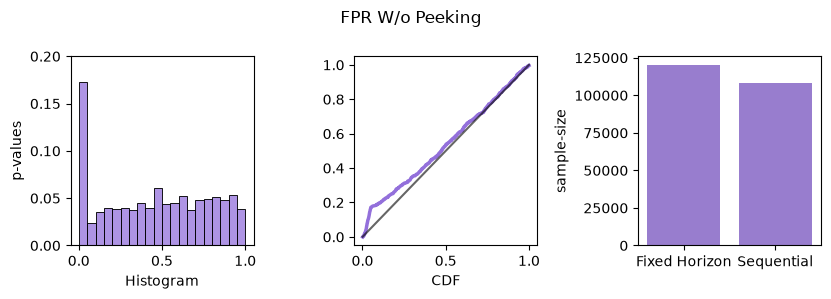

In [180]:
abtest_dignostic_plot(aatest_wo_peeking, p_distribution, 120000, average_sample_size, "FPR W/o Peeking")


In [224]:
peeking_freq = 10
total_sample_size = 12000
p_thersold = 0.05
peeking_sample_size = np.linspace(0, 120000, peeking_freq+1 , dtype=int)[1:]
p_value_thresholds = np.repeat(p_thersold, peeking_freq)
for freq in range(peeking_freq):
    peek_no = freq + 1
    p_sim_ratio, average_sample_size, p_distribution = abtest_wo_es_power.simulation_func(1000, p_value_thresholds[freq], peek_no)
    print(p_sim_ratio, average_sample_size)

0.796 120000.0
0.831 88620.0
0.829 79640.0
0.835 73890.0
0.842 68616.0
0.839 67860.0
0.841 65896.692
0.853 62550.0
0.856 61866.367
0.858 61008.0


In [8]:
vv = v_A.generateClicks(100)
vv.sum()

np.int64(8)

In [ ]:
def boundry_thresholds(alpha, beta):
    a = np.log( beta / (1-alpha) )
    b = np.log( (1-beta) / alpha )

    return a, b



def log_liklihood_ratio_binomial_func(baseline_ctr, mde, clicks, non_clicks):

    p1 = baseline_ctr + mde
    p0 = baseline_ctr

    part1 = clicks * np.log(p1/p0)
    part2 = non_clicks * np.log((1-p1)/(1-p0))

    log_delta = part1 + part2

    return log_delta



In [ ]:
baseline_ctr = 0.05
mde = 0.0025
a, b = np.round(boundry_thresholds(0.05, 0.20), 3)
print(a,b)
total_sample_size = 120000

dump_size = 1000


simulation_trials = int(total_sample_size/dump_size)
observed_data_logs = np.array([])
lambda_logs = np.zeros(simulation_trials)

for i in range(simulation_trials):

    sample_data = v_A.generateClicks(dump_size)
    observed_data_logs = np.concatenate((observed_data_logs, sample_data))
    clicks = observed_data_logs.sum()
    non_clicks = len(observed_data_logs) - clicks

    lambda_ = log_liklihood_ratio_binomial_func(baseline_ctr=baseline_ctr,
                                                mde=mde,
                                                clicks=clicks,
                                                non_clicks=non_clicks)
    #print(lambda_)
    lambda_logs[i] = lambda_
    print(len(observed_data_logs))
    if lambda_ >= b:
        print("Accept Alternative Hypothesis")
        break
    elif lambda_ <= a:
        print("Accept Null Hypothesis")
        break
    else:
        continue
    
    print(clicks)
    print(non_clicks)
    print(lambda_)




lambda_logs = lambda_logs[lambda_logs != 0]
used_sample_size = len(observed_data_logs)
print(lambda_logs)


-1.558 2.773
Accept Null Hypothesis
[-0.37233832 -1.10465312 -1.01416453 -1.180802   -1.0388882  -1.3083761
 -1.11503709 -1.33309977 -1.60258766]


In [85]:
len(observed_data_logs)

9000

In [ ]:
def SPRT_Test(total_sample_size,
              dump_size,
              baseline_ctr,
              mde,
              upper_boundry,
              lower_boundry,
              test_version):
    
    simulation_trials = int(total_sample_size/dump_size)
    observed_data_logs = np.array([])
    lambda_logs = np.zeros(simulation_trials)

    for i in range(simulation_trials):
        
        sample_data = test_version.generateClicks(dump_size)
        observed_data_logs = np.concatenate((observed_data_logs, sample_data))
        clicks = observed_data_logs.sum()
        non_clicks = len(observed_data_logs) - clicks

        lambda_ = log_liklihood_ratio_binomial_func(baseline_ctr=baseline_ctr,
                                                mde=mde,
                                                clicks=clicks,
                                                non_clicks=non_clicks)
        #print(lambda_)
        lambda_logs[i] = lambda_
        #print(len(observed_data_logs))
        
        if lambda_ >= upper_boundry:
            print("Accept Alternative Hypothesis")
            break
        elif lambda_ <= lower_boundry:
            print("Accept Null Hypothesis")
            break
        else:
            continue
    

    lambda_logs = lambda_logs[lambda_logs != 0]
    used_sample_size = len(observed_data_logs)
    #print(lambda_logs)

    return lambda_logs, used_sample_size

In [101]:
SPRT_Test(total_sample_size=total_sample_size,
          dump_size =dump_size,
          baseline_ctr = baseline_ctr,
          mde = mde,
          upper_boundry=b,
          lower_boundry=a,
          test_version=v_B)

Accept Alternative Hypothesis


(array([-0.11521226,  0.18097718, -0.19136114, -0.40942383, -0.83318736,
        -0.99982483, -0.85791103, -0.6131468 , -0.05983131, -0.02076793,
         0.48112235,  0.62303615,  0.71352473,  0.2897612 ,  0.27739937,
        -0.04351374, -0.77582854, -1.04531643, -1.16052869, -1.01861489,
        -0.92812631, -0.58051166, -0.59287349, -0.29668406, -0.3090459 ,
         0.44997045,  0.59188425,  1.45375101,  1.28711354,  1.78900382,
         2.18804368,  2.22710706,  2.16332001,  2.81948593]),
 34000)

In [ ]:
simulation_trials = 10
p_hits_
for i in range(simulation_trials):


In [116]:
class SPRT_Test:

    def __init__(self,total_sample_size, dump_size, baseline_ctr, mde, test_version ):
        self.total_sample_size = total_sample_size
        self.dump_size = dump_size
        self.baseline_ctr = baseline_ctr
        self.mde = mde
        self.test_version = test_version

    def boundry_thresholds(self, alpha, beta):
        
        a = np.log( beta / (1-alpha) )
        b = np.log( (1-beta) / alpha )

        return np.round((a, b),4)
    
     
    def log_liklihood_ratio_binomial_func(self, baseline_ctr, mde, clicks, non_clicks):
        
        p1 = baseline_ctr + mde
        p0 = baseline_ctr

        part1 = clicks * np.log(p1/p0)
        part2 = non_clicks * np.log((1-p1)/(1-p0))

        log_delta = part1 + part2

        return log_delta

    def SPRT_Test(self, upper_boundry, lower_boundry):
         
         total_steps = int(self.total_sample_size/ self.dump_size)
         observed_data_logs = np.array([])
         lambda_logs = np.zeros(total_steps)

         for i in range(total_steps):
             
             sample_data = self.test_version.generateClicks(dump_size)
             observed_data_logs = np.concatenate((observed_data_logs, sample_data))
             clicks = observed_data_logs.sum()
             non_clicks = len(observed_data_logs) - clicks

             lambda_ = self.log_liklihood_ratio_binomial_func(baseline_ctr=self.baseline_ctr,
                                                         mde=self.mde,
                                                         clicks=clicks,
                                                         non_clicks=non_clicks)
             #print(lambda_)
             lambda_logs[i] = lambda_
             #print(len(observed_data_logs))
        
             if lambda_ >= upper_boundry:
                  #print("Accept Alternative Hypothesis")
                  break
             elif lambda_ <= lower_boundry:
                  #print("Accept Null Hypothesis")
                  break
             else:
                 continue
    

         lambda_logs = lambda_logs[lambda_logs != 0]
         used_sample_size = len(observed_data_logs)
         #print(lambda_logs)

         return lambda_logs, used_sample_size

    def sprt_simulation(self, simulation_trials, upper_boundry, lower_boundry):
        
        p_hits_b = 0
        p_hits_a = 0
        sample_size = 0
        for i in range(simulation_trials):
            
            lambda_logs, used_sample_size =  self.SPRT_Test(upper_boundry,lower_boundry)
            critical_value = lambda_logs[-1]
            #print(critical_value)
            sample_size = sample_size + used_sample_size

            if critical_value >= b:
                p_hits_b = p_hits_b + 1
                #print(f"p_hits_b {p_hits_b}")
        
            if critical_value <=a:
                p_hits_a = p_hits_a + 1
                #print(f"p_hits_a {p_hits_a}")

        #print(p_hits_b, p_hits_a)
        fpr_rate = np.round(1 - (p_hits_a/simulation_trials),3)
        power_rate = np.round((p_hits_b/simulation_trials),3)
        #print(fpr_rate, power_rate)
        return fpr_rate, power_rate 
    
    

In [120]:
total_sample_size = 120000
dump_size = 1000
baseline_ctr = 0.05
mde = 0.0025


aatest_sprt = SPRT_Test(total_sample_size=total_sample_size,
                        dump_size =dump_size,
                        baseline_ctr = baseline_ctr,
                        mde = mde,
                        test_version=v_B)




In [121]:
a, b = aatest_sprt.boundry_thresholds(alpha=0.05, beta=0.20)
print(a,b)

-1.5581 2.7726


In [122]:
aatest_sprt.sprt_simulation(1000, b, a)

(np.float64(0.848), np.float64(0.836))

In [ ]:
p_hits_b = 0
p_hits_a = 0
sample_size = 0
for i in range(1000):
    lambda_logs, used_sample_size =  aatest_sprt.SPRT_Test(b,a)
    critical_value = lambda_logs[-1]
    #print(critical_value)
    sample_size = sample_size + used_sample_size

    if critical_value >= b:
        p_hits_b = p_hits_b + 1
        #print(f"p_hits_b {p_hits_b}")
        
    if critical_value <=a:
        p_hits_a = p_hits_a + 1
        #print(f"p_hits_a {p_hits_a}")

print(p_hits_b, p_hits_a)
fpr_rate = np.round(1 - (p_hits_a/1000),3)
power_rate = np.round((p_hits_b/1000),3)
print(fpr_rate, power_rate)

Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Alternative Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Alternative Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Alternative Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null Hypothesis
Accept Null H

In [98]:
p_hits_b

47

In [99]:
p_hits_a

951

<Axes: ylabel='Count'>

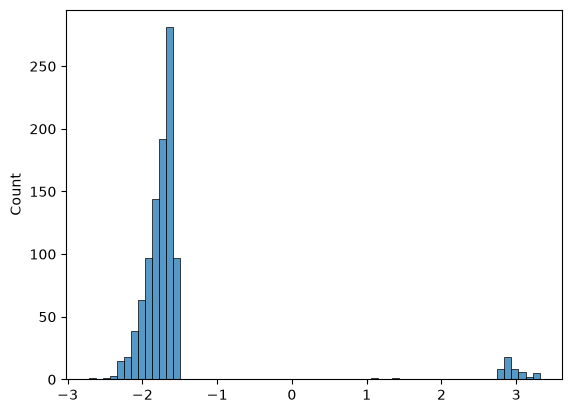

In [100]:
sns.histplot(lambda_distribution)

In [102]:
sample_size/1000

23905.0

In [111]:
def sprt_simulation(simulation_trials, test_object,upper_boundry, lower_boundry):
   
   p_hits_b = 0
   p_hits_a = 0
   sample_size = 0
   for i in range(simulation_trials):
    
    lambda_logs, used_sample_size =  test_object.SPRT_Test(upper_boundry,lower_boundry)
    critical_value = lambda_logs[-1]
    #print(critical_value)
    sample_size = sample_size + used_sample_size

    if critical_value >= b:
       p_hits_b = p_hits_b + 1
       #print(f"p_hits_b {p_hits_b}")
        
    if critical_value <=a:
       p_hits_a = p_hits_a + 1
        #print(f"p_hits_a {p_hits_a}")

   #print(p_hits_b, p_hits_a)
   fpr_rate = np.round(1 - (p_hits_a/simulation_trials),3)
   power_rate = np.round((p_hits_b/simulation_trials),3)
   #print(fpr_rate, power_rate)
   return fpr_rate, power_rate 

In [112]:
sprt_simulation(1000,aatest_sprt, b,a)

(np.float64(0.046), np.float64(0.041))